<a href="https://colab.research.google.com/github/Nasim-Amani/ramp-aware-solar/blob/main/E1_target_(value_vs_change)_%C3%97_loss_(MSE_vs_ramp_aware)%2C_irradiance_only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ramp-aware LSTM forecasting of solar irradiance (10–60 s ahead)

## Aim
We forecast solar irradiance 10 to 60 seconds ahead with an LSTM, and study how well the forecasts capture **ramps**: sudden changes in irradiance caused by passing clouds. Standard models are trained and judged with MSE/RMSE, which rewards smooth forecasts. Such models can beat persistence on RMSE and still miss most ramps, which are the events that matter most for grid and battery control.

## What the data exploration showed
- Ramps occur almost only on broken-cloud days, are real (confirmed by an independent PV module) and are fast: most are completed within 10 s, and the sun often stays blocked for only about 20 s.
- On clear days persistence is almost perfect up to one minute; on broken-cloud days its error doubles within the first minute.
- From the past, the **chance** of a ramp is predictable, but its **exact timing and direction** hardly are. Ramps come in groups: once the sky becomes restless (many fast ups and downs from passing clouds), it usually stays restless for several minutes or longer, while calm periods also tend to stay calm. A model can therefore tell from the last few minutes whether a ramp is likely soon, but not exactly when the next cloud edge will arrive.

## Research questions
1. **Does a ramp-aware loss help?** Does adding a term on the size of the 10-s changes to the MSE loss improve ramp detection, and how much accuracy (RMSE skill) does it cost?
2. **Should the model predict the change instead of the value?** Does predicting the change from the current irradiance (and adding it to the current value) improve the forecasts, especially on clear days where persistence is almost perfect?
3. **Which inputs help?** Do time of day and measures of recent variability improve accuracy or ramp detection, compared with irradiance alone?
4. **What is the trade-off?** How do accuracy and ramp detection change as the weight λ of the ramp term increases?
5. **How robust are the results?** Do the conclusions hold for different lead times (10–60 s), for clear and broken-cloud days, and when each broken-cloud day is used as the test day?

## Experiments

| | Question | What changes |
|---|---|---|
| **E1** | 1 and 2 | target (value vs change) × loss (MSE vs ramp-aware), irradiance only |
| **E2** | 3 | + time of day |
| **E3** | 3 | + recent-variability features |
| **E4** | 4 | weight λ of the ramp term (0, 0.5, 1, 3, 10) |
| **E5** | 5 | each broken-cloud day used as the test day in turn |

**This notebook runs E1.**

## 1. Settings
All choices that stay fixed across the experiments are set here. For a first look, each setup is trained with one random seed; more seeds can be added later by changing `SEEDS` (finished runs are skipped).

Results are written to a CSV file after every run. If Colab disconnects, re-running the notebook skips the runs that are already done.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

STEP_S   = 10                          # resolution: 10-s averages
LOOKBACK = 60                          # input:  the last 60 steps (10 min)
HORIZON  = 6                           # output: the next 6 steps (10, 20, ..., 60 s)
LEADS    = STEP_S * np.arange(1, HORIZON + 1)
SEEDS    = [0]                         # first look: one seed per setup (later: [0, 1, 2])

HP = {"units": 64, "learning_rate": 1e-3, "batch_size": 128,
      "max_epochs": 100, "patience": 10}   # same for all setups (tuning comes later)

RESULTS_FILE = "E1_results.csv"        # one row per run

## 2. Data
1-s irradiance (`Solar_Rad_clean`), daylight records of the 11 complete days, averaged to 10 s (the model resolution chosen in the data exploration). Only irradiance is used as input in E1.

In [ ]:
df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])

data = (df.loc[df["full_day"] & df["daylight"], ["Solar_Rad_clean"]]
          .rename(columns={"Solar_Rad_clean": "G"})        # G = irradiance (W/m²)
          .resample(f"{STEP_S}s").mean()
          .dropna())     # removes only the night steps (checked: no NaN and no gaps inside daylight)

print(f"10-s daylight steps: {len(data):,}")

10-s daylight steps: 46,794


## 3. Split and day types
- **Split by whole days, in time order:** train 16–23 Feb, validation 24 Feb, test 25 Feb (broken clouds) and 26 Feb (clear).
- **Day types** come from the Variability Index in the data exploration notebook.

In [ ]:
days = sorted(set(data.index.date))
TRAIN_DAYS, VAL_DAYS, TEST_DAYS = days[:8], days[8:9], days[9:]

# Day types from the Variability Index (data exploration notebook)
DAY_TYPE = {pd.Timestamp(d).date(): typ for d, typ in {
    "2013-02-16": "clear",         "2013-02-17": "few clouds",    "2013-02-18": "broken clouds",
    "2013-02-19": "clear",         "2013-02-20": "broken clouds", "2013-02-21": "clear",
    "2013-02-22": "clear",         "2013-02-23": "few clouds",    "2013-02-24": "broken clouds",
    "2013-02-25": "broken clouds", "2013-02-26": "clear"}.items()}

for name, dl in [("train", TRAIN_DAYS), ("validation", VAL_DAYS), ("test", TEST_DAYS)]:
    print(f"{name:11s}", ", ".join(f"{d:%d %b} ({DAY_TYPE[d]})" for d in dl))

train       16 Feb (clear), 17 Feb (few clouds), 18 Feb (broken clouds), 19 Feb (clear), 20 Feb (broken clouds), 21 Feb (clear), 22 Feb (clear), 23 Feb (few clouds)
validation  24 Feb (broken clouds)
test        25 Feb (broken clouds), 26 Feb (clear)


## 4. Ramp threshold

**Goal:** decide how large a 10-s change must be to count as a ramp, based on the data.

1. **10-s changes.** For each day, we subtract each 10-s value from the next one, e.g. 790 → 650 W/m² gives a change of −140 W/m². Changes are only computed between values that are exactly 10 s apart.
2. **Which days.** We use only the broken-cloud **training** days (18 and 20 Feb): clear days have almost only tiny changes, and the test days must not influence a threshold that is later used to score the models. Drops and rises are treated the same, so we use the size of each change (−140 and +140 both count as 140).
3. **Threshold.** A ramp is a change among the largest 5 % of these changes, i.e. larger than their 95th percentile. Rounded to 10 W/m², this gives **80 W/m² per 10 s**.

All ramp results use this threshold. As a sensitivity check, we also report results at 60 W/m².

In [ ]:
def changes_of_day(day):
    # 10-s changes of irradiance within one day, only between real neighbouring steps
    g = data.loc[data.index.date == day, "G"]
    ok = g.index.to_series().diff() == pd.Timedelta(seconds=STEP_S)
    return g.diff()[ok]

broken_train = [d for d in TRAIN_DAYS if DAY_TYPE[d] == "broken clouds"]
train_changes = pd.concat([changes_of_day(d) for d in broken_train]).abs()

THRESHOLD       = int(round(np.percentile(train_changes, 95), -1))   # main threshold (W/m² per 10 s)
THRESHOLD_CHECK = 60                                                  # sensitivity check
print(f"Ramp threshold: {THRESHOLD} W/m² per 10 s   (check: {THRESHOLD_CHECK})")

Ramp threshold: 80 W/m² per 10 s   (check: 60)


## 5. Training examples (windows)

Each training example is a **window** of 66 consecutive 10-s values: the first 60 (10 min) are the input, and the next 6 (10, 20, …, 60 s) are the targets. We slide this window forward one step at a time to create many examples.

- **One day per window.** Because the nights were removed, the last value of one day is directly followed by the first value of the next morning in the data, although 12 hours lie between them. We therefore cut windows inside each day separately, so no example mixes the evening of one day with the morning of the next.
- **No gaps.** A window is used only if its 66 values are exactly 10 s apart; windows with a missing step are skipped.
- **Current value.** For each example we also keep the current irradiance ("now", the last input value), which is needed for persistence and for the change target.

In [ ]:
def make_windows(days_list, inputs):
    # Returns X (examples, LOOKBACK, features), Y (examples, HORIZON) in W/m²,
    # now (examples, 1) = irradiance at the forecast time, and the forecast times
    X, Y, now, t = [], [], [], []
    span = pd.Timedelta(seconds=STEP_S * (LOOKBACK + HORIZON - 1))
    for day in days_list:
        d = data[data.index.date == day]
        n = len(d) - LOOKBACK - HORIZON + 1
        if n <= 0:
            continue
        start = np.arange(n)
        ok = (d.index[start + LOOKBACK + HORIZON - 1] - d.index[start]) == span   # no missing step inside
        x = np.lib.stride_tricks.sliding_window_view(d[inputs].to_numpy(), LOOKBACK, axis=0)[:n]
        y = np.lib.stride_tricks.sliding_window_view(d["G"].to_numpy(), HORIZON)[LOOKBACK:LOOKBACK + n]
        X.append(x.transpose(0, 2, 1)[ok])
        Y.append(y[ok])
        now.append(d["G"].to_numpy()[start + LOOKBACK - 1][ok])
        t.append(d.index[start + LOOKBACK - 1][ok])
    return (np.concatenate(X), np.concatenate(Y),
            np.concatenate(now)[:, None], pd.DatetimeIndex(np.concatenate(t)))


_windows = {}                          # windows are built once per input set and reused
def get_windows(inputs):
    key = tuple(inputs)
    if key not in _windows:
        _windows[key] = {name: make_windows(dl, inputs)
                         for name, dl in [("train", TRAIN_DAYS), ("val", VAL_DAYS), ("test", TEST_DAYS)]}
    return _windows[key]

w = get_windows(["G"])
print({name: len(v[0]) for name, v in w.items()}, " input shape:", w["train"][0].shape)

{'train': 33410, 'val': 4213, 'test': 8456}  input shape: (33410, 60, 1)


## 6. Loss function

We use one loss function for all four setups:

$$L = \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(\hat G_{t+k} - G_{t+k}\big)^2}_{\text{error in the values}} \;+\; \lambda \cdot \underbrace{\frac{1}{6}\sum_{k=1}^{6}\big(|\Delta \hat G_{t+k}| - |\Delta G_{t+k}|\big)^2}_{\text{error in the size of each 10-s change}}$$

(averaged over all examples), where $\Delta G_{t+k} = G_{t+k} - G_{t+k-1}$ is the change from one 10-s step to the next along the forecast path, starting from the current value $G_t$.

- The **first term** is the usual MSE.
- The **second term** compares the *size* of each predicted change with the real one, so a forecast that is too smooth is penalised, even if the timing of a ramp is slightly wrong. It is the gradient difference loss of Mathieu et al. (2016), originally proposed to reduce blurry predictions in video forecasting, applied here along the time axis of the forecast path.
- **λ = 0** gives plain MSE; **λ = 1** is our ramp-aware loss.

The same loss is used for both targets (value and change), since the 10-s changes along the path are the same in both cases. To score the first step (from "now" to +10 s), the loss needs the current value, so we pass it as an extra first column of the targets.

## Manuscript notes: loss function and references

### What to cite, and for what

| Paper | Use in the manuscript |
|---|---|
| **Mathieu, Couprie & LeCun (2016)** | Direct source of our ramp term: the *gradient difference loss* (GDL), proposed to reduce blurry predictions in video forecasting |
| **Subich, Husain, Separovic & Yang (2025)** | Motivation: the *double penalty* of MSE, which makes data-driven forecasts too smooth |
| **Le Guen & Thome (2019)** | Related loss for sharp changes in time-series forecasts (DILATE); candidate for comparison |
| **Nouri et al. (2024)** | Ramp evaluation: precision, recall and F1 with a timing tolerance |

### Key points from each paper
- **Mathieu et al. (2016):** an ℓ2 loss produces blurry predictions. Their fix penalises the difference between the *size* of real and predicted changes between neighbouring pixels:
  $$L_{gdl} = \sum_{i} \big|\,|Y_i - Y_{i-1}| - |\hat Y_i - \hat Y_{i-1}|\,\big|^{\alpha}$$
  Our ramp term is this loss with $\alpha = 2$, applied **along time** (the 10-s steps of the forecast path) instead of across neighbouring pixels.
- **Subich et al. (2025):** under MSE, a sharp feature that is predicted slightly too early or too late is penalised twice, so models learn to smooth. They fix this in global weather forecasting with a loss that separates the amplitude of features from their position.
- **Le Guen & Thome (2019):** DILATE combines a shape term and a time-distortion term so that forecasts keep sharp changes; designed for time series.
- **Nouri et al. (2024):** an RMSE-optimised model can have good skill but detect ramps poorly; they propose ramp-based precision, recall and F1 with a timing tolerance.

### Our loss (Methods section)

$$L = \frac{1}{6}\sum_{k=1}^{6}\big(\hat G_{t+k} - G_{t+k}\big)^2 \;+\; \lambda \cdot \frac{1}{6}\sum_{k=1}^{6}\big(|\Delta \hat G_{t+k}| - |\Delta G_{t+k}|\big)^2$$

with $\Delta G_{t+k} = G_{t+k} - G_{t+k-1}$ along the forecast path, starting from the current value $G_t$. λ = 0 gives plain MSE.

### Novelty: how to position it
The loss formula itself is **not new**; it is an established idea from video prediction. Our contribution is:
1. applying it to **seconds-to-minutes solar irradiance forecasting** from 1-s field data, where ramps are fast (72 % within one 10-s step) and short (median shade 20 s);
2. evaluating it with a **ramp metric**, not only RMSE;
3. quantifying the **trade-off** between accuracy and ramp detection, and how it depends on λ, lead time and sky conditions.

A known loss applied to a new problem, with careful evaluation, is a stronger and more honest claim than presenting the loss as new.

### Ready-to-use sentences
- *Methods:* "The ramp term is the gradient difference loss of Mathieu et al. (2016), applied along the time axis of the forecast path. It addresses the double-penalty effect of MSE training (Subich et al., 2025), which leads to smooth forecasts that miss sharp changes."
- *Introduction:* "Models trained with MSE can achieve good RMSE and skill scores while detecting few ramps (Nouri et al., 2024). Under MSE, a sharp change predicted slightly too early or too late is penalised twice, so models learn to smooth (Subich et al., 2025). Losses that also penalise errors in the size of changes have reduced such smoothing in video prediction (Mathieu et al., 2016) and time-series forecasting (Le Guen & Thome, 2019), but have not been tested for seconds-to-minutes solar ramp forecasting."
- *Evaluation:* "Ramp detection is evaluated with precision, recall and F1 using a timing tolerance of ±10 s, following Nouri et al. (2024)."

### References
- Le Guen, V., & Thome, N. (2019). Shape and time distortion loss for training deep time series forecasting models. *Advances in Neural Information Processing Systems (NeurIPS)*, 32.
- Mathieu, M., Couprie, C., & LeCun, Y. (2016). Deep multi-scale video prediction beyond mean square error. *International Conference on Learning Representations (ICLR)*. arXiv:1511.05440.
- Nouri, B., Fabel, Y., Blum, N., Schnaus, D., Zarzalejo, L. F., Kazantzidis, A., & Wilbert, S. (2024). Ramp rate metric suitable for solar forecasting. *Solar RRL*, 2400468. https://doi.org/10.1002/solr.202400468
- Subich, C., Husain, S. Z., Separovic, L., & Yang, J. (2025). Fixing the double penalty in data-driven weather forecasting through a modified spherical harmonic loss function. arXiv:2501.19374.

In [ ]:
def ramp_aware_loss(lam):
    def loss(y_true, y_pred):
        start, y = y_true[:, :1], y_true[:, 1:]          # first column = start of the path ("now")
        path_true = tf.concat([start, y], axis=1)
        path_pred = tf.concat([start, y_pred], axis=1)
        step_true = path_true[:, 1:] - path_true[:, :-1]  # real 10-s changes
        step_pred = path_pred[:, 1:] - path_pred[:, :-1]  # predicted 10-s changes
        mse_values = tf.reduce_mean(tf.square(y - y_pred))
        mse_size   = tf.reduce_mean(tf.square(tf.abs(step_pred) - tf.abs(step_true)))
        return mse_values + lam * mse_size
    return loss

## 7. Evaluation
- **Skill** against persistence: $1 - \text{RMSE}_{model} / \text{RMSE}_{persistence}$ (in %), for each lead time and for each day type.
- **Ramps** on the broken-cloud test day: each forecast is a path now → +10 s → … → +60 s. A ramp is a step in the path larger than the threshold. A predicted ramp counts as correct if the measured path has a ramp in the same direction within ±1 step (±10 s). We report precision, recall and F1.

In [ ]:
TOL = 1                                          # timing tolerance: ±1 step (±10 s)

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

def widen(mask, tol):
    # mark each event and its ±tol neighbouring steps along the path
    out = mask.copy()
    for s in range(1, tol + 1):
        out[:, s:]  |= mask[:, :-s]
        out[:, :-s] |= mask[:, s:]
    return out

def ramp_scores(obs, pred, thr):
    # precision, recall and F1 for up- and down-ramps together
    hit_obs = hit_pred = n_obs = n_pred = 0
    for sign in (+1, -1):
        o, p = sign * obs > thr, sign * pred > thr
        hit_obs  += (o & widen(p, TOL)).sum()     # measured ramps that were predicted
        hit_pred += (p & widen(o, TOL)).sum()     # predicted ramps that really happened
        n_obs, n_pred = n_obs + o.sum(), n_pred + p.sum()
    recall    = hit_obs / n_obs if n_obs else np.nan
    precision = hit_pred / n_pred if n_pred else np.nan
    f1 = 2 * precision * recall / (precision + recall) if n_pred and (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "F1": f1}

def evaluate(P, Y, now, t):
    # all scores of one set of test forecasts P (W/m²)
    pers  = np.repeat(now, HORIZON, axis=1)                    # persistence forecast
    types = np.array([DAY_TYPE[d] for d in t.date])
    res = {"skill all": 100 * (1 - rmse(Y, P) / rmse(Y, pers))}
    for typ in ["broken clouds", "clear"]:
        m = types == typ
        res[f"skill {typ}"] = 100 * (1 - rmse(Y[m], P[m]) / rmse(Y[m], pers[m]))
        res[f"RMSE {typ}"]  = rmse(Y[m], P[m])
    for k, lead in enumerate(LEADS):
        res[f"skill {lead}s"] = 100 * (1 - rmse(Y[:, k], P[:, k]) / rmse(Y[:, k], pers[:, k]))
    m = types == "broken clouds"                               # ramps: broken-cloud test day
    obs  = np.diff(np.hstack([now, Y]), axis=1)[m]
    pred = np.diff(np.hstack([now, P]), axis=1)[m]
    for thr in [THRESHOLD, THRESHOLD_CHECK]:
        res.update({f"{k} @{thr}": v for k, v in ramp_scores(obs, pred, thr).items()})
    return res

# Reference: persistence on the test days
_, Y_te, now_te, t_te = get_windows(["G"])["test"]
ref = evaluate(np.repeat(now_te, HORIZON, axis=1), Y_te, now_te, t_te)
print(f"Persistence RMSE: broken-cloud day {ref['RMSE broken clouds']:.1f} W/m², "
      f"clear day {ref['RMSE clear']:.1f} W/m²   (persistence never predicts a ramp)")

Persistence RMSE: broken-cloud day 89.8 W/m², clear day 2.2 W/m²   (persistence never predicts a ramp)


## 8. One experiment = one function call
`run_experiment(target, lam, inputs, seed)` builds the training data, trains the LSTM and returns all scores.

- **target = "level":** the network predicts the irradiance values (scaled 0–1).
- **target = "change":** the network predicts the change from the current value, and the forecast is *now + change*. Its output layer starts at zero, so the untrained model equals persistence.

Both targets use the same scale (the range of irradiance on the training days), so their losses are comparable. Inputs are min-max scaled with the training data only.

In [ ]:
def run_experiment(target, lam, inputs, seed):
    (X_tr, Y_tr, now_tr, _), (X_va, Y_va, now_va, _), (X_te, Y_te, now_te, t_te) = get_windows(inputs).values()

    # ---- Scaling (training data only) ----
    x_min = X_tr.reshape(-1, len(inputs)).min(axis=0)
    x_max = X_tr.reshape(-1, len(inputs)).max(axis=0)
    scale_x = lambda X: (X - x_min) / (x_max - x_min)
    y_min, y_scale = Y_tr.min(), Y_tr.max() - Y_tr.min()

    def to_target(Y, now):
        # what the network learns; the first column is the start of the path (for the loss)
        if target == "level":
            return np.hstack([(now - y_min) / y_scale, (Y - y_min) / y_scale])
        return np.hstack([np.zeros_like(now), (Y - now) / y_scale])

    def to_wm2(P, now):
        # network output back to irradiance (W/m²)
        P = P * y_scale + (y_min if target == "level" else now)
        return np.clip(P, 0, None)

    # ---- Model ----
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(LOOKBACK, len(inputs))),
        tf.keras.layers.LSTM(HP["units"]),
        tf.keras.layers.Dense(HORIZON, kernel_initializer="zeros" if target == "change" else "glorot_uniform"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(HP["learning_rate"]), loss=ramp_aware_loss(lam))

    # ---- Training with early stopping on the validation day ----
    stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["patience"], restore_best_weights=True)
    hist = model.fit(scale_x(X_tr), to_target(Y_tr, now_tr),
                     validation_data=(scale_x(X_va), to_target(Y_va, now_va)),
                     epochs=HP["max_epochs"], batch_size=HP["batch_size"], callbacks=[stop],
                     verbose=2)                                    # one line per epoch

    # ---- Training curve of this run ----
    best = int(np.argmin(hist.history["val_loss"])) + 1
    plt.figure(figsize=(5, 3))
    plt.plot(hist.history["loss"], label="train")
    plt.plot(hist.history["val_loss"], label="validation")
    plt.axvline(best - 1, color="gray", ls="--", lw=0.8, label=f"best epoch ({best})")
    plt.title(f"{target}, λ = {lam}, seed {seed}"); plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.legend(); plt.tight_layout(); plt.show()

    # ---- Test forecasts and scores ----
    P = to_wm2(model.predict(scale_x(X_te), verbose=0), now_te)
    np.save(f"pred_{target}_lam{lam}_seed{seed}.npy", P)          # keep the test forecasts (W/m²) for the result tables
    res = {"target": target, "lambda": lam, "inputs": "+".join(inputs), "seed": seed,
           "best epoch": best}
    res.update(evaluate(P, Y_te, now_te, t_te))
    return res

## 9. Run E1: target × loss
Four setups with one seed each (4 runs), input = irradiance only. Training runs for at most 100 epochs; early stopping ends it when the validation loss has not improved for 10 epochs and restores the best epoch. Each finished run (scores and test forecasts) is saved immediately.

The model is small, so a CPU runtime is enough; 4 runs take roughly 40 minutes.

Epoch 1/100
262/262 - 22s - 84ms/step - loss: 0.0119 - val_loss: 0.0038
Epoch 2/100
262/262 - 22s - 84ms/step - loss: 0.0020 - val_loss: 0.0037
Epoch 3/100
262/262 - 20s - 75ms/step - loss: 0.0019 - val_loss: 0.0037
Epoch 4/100
262/262 - 22s - 86ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 5/100
262/262 - 20s - 75ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 22s - 84ms/step - loss: 0.0017 - val_loss: 0.0034
Epoch 7/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0033
Epoch 8/100
262/262 - 20s - 77ms/step - loss: 0.0016 - val_loss: 0.0032
Epoch 9/100
262/262 - 20s - 78ms/step - loss: 0.0015 - val_loss: 0.0032
Epoch 10/100
262/262 - 20s - 76ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 11/100
262/262 - 22s - 83ms/step - loss: 0.0015 - val_loss: 0.0031
Epoch 12/100
262/262 - 41s - 155ms/step - loss: 0.0015 - val_loss: 0.0030
Epoch 13/100
262/262 - 19s - 74ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 14/100
262/262 - 22s - 84ms/step - loss: 0.0014 - val

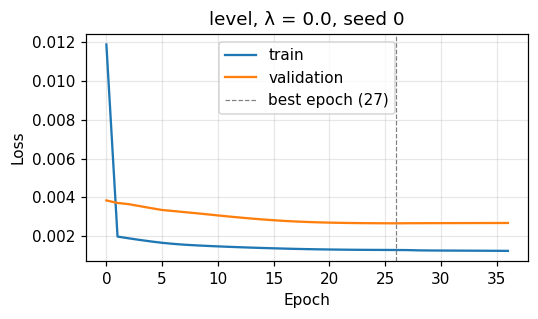

level  λ=0.0  seed=0  epochs= 27  skill=  5.7 %  F1@80=0.003
Epoch 1/100
262/262 - 24s - 90ms/step - loss: 0.0142 - val_loss: 0.0047
Epoch 2/100
262/262 - 20s - 75ms/step - loss: 0.0025 - val_loss: 0.0046
Epoch 3/100
262/262 - 22s - 82ms/step - loss: 0.0023 - val_loss: 0.0045
Epoch 4/100
262/262 - 20s - 76ms/step - loss: 0.0022 - val_loss: 0.0044
Epoch 5/100
262/262 - 22s - 85ms/step - loss: 0.0022 - val_loss: 0.0043
Epoch 6/100
262/262 - 20s - 76ms/step - loss: 0.0021 - val_loss: 0.0042
Epoch 7/100
262/262 - 22s - 84ms/step - loss: 0.0020 - val_loss: 0.0041
Epoch 8/100
262/262 - 20s - 78ms/step - loss: 0.0020 - val_loss: 0.0040
Epoch 9/100
262/262 - 22s - 83ms/step - loss: 0.0019 - val_loss: 0.0039
Epoch 10/100
262/262 - 20s - 77ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 11/100
262/262 - 21s - 81ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 12/100
262/262 - 20s - 76ms/step - loss: 0.0018 - val_loss: 0.0037
Epoch 13/100
262/262 - 20s - 75ms/step - loss: 0.0018 - val_loss: 0.0037

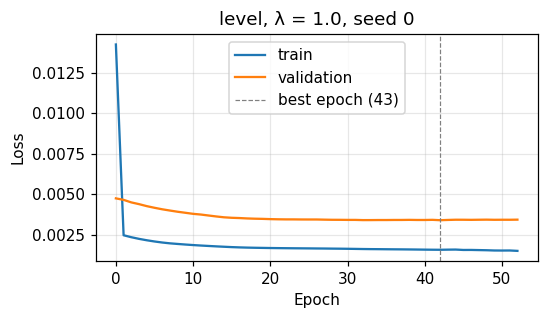

level  λ=1.0  seed=0  epochs= 43  skill=  1.2 %  F1@80=0.154
Epoch 1/100
262/262 - 23s - 86ms/step - loss: 0.0014 - val_loss: 0.0030
Epoch 2/100
262/262 - 22s - 86ms/step - loss: 0.0014 - val_loss: 0.0029
Epoch 3/100
262/262 - 20s - 78ms/step - loss: 0.0013 - val_loss: 0.0028
Epoch 4/100
262/262 - 22s - 86ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 5/100
262/262 - 40s - 152ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 6/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 7/100
262/262 - 21s - 82ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 8/100
262/262 - 20s - 75ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 9/100
262/262 - 23s - 86ms/step - loss: 0.0013 - val_loss: 0.0027
Epoch 10/100
262/262 - 19s - 74ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 11/100
262/262 - 21s - 81ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 12/100
262/262 - 20s - 75ms/step - loss: 0.0012 - val_loss: 0.0027
Epoch 13/100
262/262 - 21s - 79ms/step - loss: 0.0012 - val_loss: 0.002

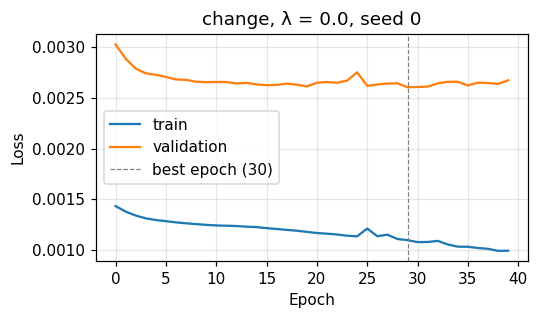

change λ=0.0  seed=0  epochs= 30  skill= -1.3 %  F1@80=0.019
Epoch 1/100
262/262 - 23s - 88ms/step - loss: 0.0019 - val_loss: 0.0038
Epoch 2/100
262/262 - 19s - 73ms/step - loss: 0.0018 - val_loss: 0.0036
Epoch 3/100
262/262 - 21s - 81ms/step - loss: 0.0017 - val_loss: 0.0036
Epoch 4/100
262/262 - 19s - 74ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 5/100
262/262 - 21s - 81ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 6/100
262/262 - 19s - 73ms/step - loss: 0.0017 - val_loss: 0.0035
Epoch 7/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 8/100
262/262 - 21s - 80ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 9/100
262/262 - 19s - 73ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 10/100
262/262 - 21s - 81ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 11/100
262/262 - 19s - 74ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 12/100
262/262 - 22s - 83ms/step - loss: 0.0016 - val_loss: 0.0034
Epoch 13/100
262/262 - 20s - 75ms/step - loss: 0.0016 - val_loss: 0.0034

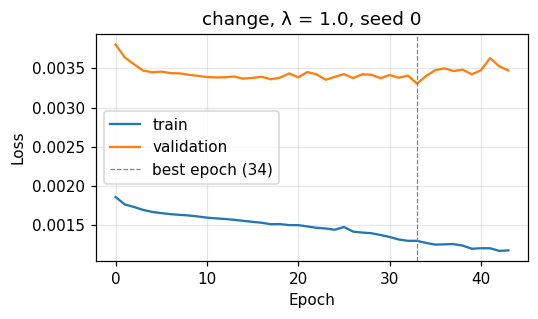

change λ=1.0  seed=0  epochs= 34  skill=-13.8 %  F1@80=0.187


In [ ]:
SETUPS = [("level", 0.0), ("level", 1.0), ("change", 0.0), ("change", 1.0)]   # (target, λ)
INPUTS = ["G"]

results = pd.read_csv(RESULTS_FILE) if os.path.exists(RESULTS_FILE) else pd.DataFrame()

for target, lam in SETUPS:
    for seed in SEEDS:
        done = (not results.empty and
                ((results["target"] == target) & (results["lambda"] == lam) & (results["seed"] == seed)).any())
        if done:
            continue                                                  # already in the CSV file
        res = run_experiment(target, lam, INPUTS, seed)
        results = pd.concat([results, pd.DataFrame([res])], ignore_index=True)
        results.to_csv(RESULTS_FILE, index=False)                    # save after every run
        print(f"{target:6s} λ={lam:<4} seed={seed}  epochs={res['best epoch']:3d}  "
              f"skill={res['skill all']:5.1f} %  F1@{THRESHOLD}={res[f'F1 @{THRESHOLD}']:.3f}")

## 10. Results

The results are computed from the saved test forecasts, so all tables use exactly the same forecasts. The four LSTM versions are named **target / loss**:

| Name | The LSTM predicts | Trained with |
|---|---|---|
| value / MSE | the irradiance values | plain MSE (the standard LSTM) |
| value / ramp-aware | the irradiance values | MSE + ramp term |
| change / MSE | the change from the current value | plain MSE |
| change / ramp-aware | the change from the current value | MSE + ramp term |

Persistence (the current value repeated for all lead times) is included as the reference.

**Metrics.** MAE, RMSE, MAPE (only where irradiance > 50 W/m², to avoid dividing by values close to 0), R² and MASE. MASE divides the MAE of a model by the MAE of the naive forecast (persistence) on the training days, for the same lead time (Hyndman & Koehler, 2006): **MASE < 1 means better than the naive forecast**, MASE > 1 worse.

In [ ]:
# =====================================================================
# A) Collect the test forecasts: persistence + every saved LSTM run
# =====================================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

MAPE_MIN = 50                                         # W/m²: MAPE only where irradiance is above this
(_, Y_tr, now_tr, _), _, (_, Y_te, now_te, t_te) = get_windows(["G"]).values()
types_te = np.array([DAY_TYPE[d] for d in t_te.date])  # day type of every test forecast

def model_name(target, lam):
    return f"{'value' if target == 'level' else 'change'} / {'MSE' if lam == 0 else 'ramp-aware'}"

forecasts = {"persistence": np.repeat(now_te, HORIZON, axis=1)}
for target, lam in SETUPS:
    for seed in SEEDS:
        file = f"pred_{target}_lam{lam}_seed{seed}.npy"
        if os.path.exists(file):
            name = model_name(target, lam) + (f" (seed {seed})" if len(SEEDS) > 1 else "")
            forecasts[name] = np.load(file)
print("Forecasts found:", list(forecasts))

# MASE scale (Hyndman & Koehler, 2006): MAE of the naive forecast (persistence) on the TRAINING days,
# for each lead time. MASE < 1 → better than the naive forecast; MASE > 1 → worse.
mase_scale = np.abs(Y_tr - now_tr).mean(axis=0)       # one value per lead time

def metrics(y, p, scale):
    big = y > MAPE_MIN
    mse = mean_squared_error(y, p)
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mse),
            "MAPE (%)": 100 * mean_absolute_percentage_error(y[big], p[big]),
            "R²": r2_score(y, p), "MASE": mean_absolute_error(y, p) / scale}

Forecasts found: ['persistence', 'value / MSE', 'value / ramp-aware', 'change / MSE', 'change / ramp-aware']


### A. Accuracy for every lead time
One table per metric: models as rows, lead times (10–60 s) as columns. Read along a row to see how a model gets worse with lead time, and down a column to compare the models at the same lead time.

In [ ]:
# =====================================================================
# B) Accuracy for every lead time (both test days together)
# =====================================================================
rows = []
for name, P in forecasts.items():
    for k, lead in enumerate(LEADS):
        rows.append({"model": name, "lead (s)": lead, **metrics(Y_te[:, k], P[:, k], mase_scale[k])})
by_lead = pd.DataFrame(rows)

# One small table per metric: models as rows, lead times as columns
for metric in ["MAE", "RMSE", "MAPE (%)", "R²", "MASE"]:
    print(f"\n{metric} per lead time (s)")
    display(by_lead.pivot(index="model", columns="lead (s)", values=metric)
                   .reindex(forecasts.keys()).round(3 if metric in ["R²", "MASE"] else 1))


MAE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,7.4,12.0,15.6,18.2,20.7,22.8
value / MSE,10.6,14.6,18.1,22.1,25.2,26.3
value / ramp-aware,11.0,15.5,20.4,21.5,25.3,27.9
change / MSE,10.2,16.0,19.6,22.5,25.4,27.4
change / ramp-aware,12.3,16.7,21.8,26.5,26.8,30.4



RMSE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,34.0,50.6,61.1,68.9,74.9,79.9
value / MSE,33.9,49.4,58.4,65.0,69.9,73.6
value / ramp-aware,37.3,51.6,62.7,66.7,72.6,77.1
change / MSE,35.5,52.6,62.7,69.8,75.6,79.4
change / ramp-aware,41.7,57.2,70.6,82.9,81.3,88.6



MAPE (%) per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,1.9,3.2,4.2,5.1,5.8,6.5
value / MSE,3.1,4.2,5.2,6.5,7.5,8.0
value / ramp-aware,3.4,5.0,6.7,6.7,8.5,9.5
change / MSE,3.1,5.1,6.3,7.3,8.3,9.1
change / ramp-aware,4.1,5.4,7.3,9.1,8.8,10.3



R² per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,0.984,0.964,0.947,0.933,0.920,0.910
value / MSE,0.984,0.965,0.952,0.940,0.931,0.923
value / ramp-aware,0.980,0.962,0.944,0.937,0.925,0.916
change / MSE,0.982,0.961,0.944,0.931,0.919,0.911
change / ramp-aware,0.975,0.954,0.929,0.903,0.906,0.889



MASE per lead time (s)


lead (s),10,20,30,40,50,60
model,,,,,,
persistence,1.627,1.679,1.730,1.712,1.716,1.716
value / MSE,2.316,2.041,2.001,2.074,2.089,1.977
value / ramp-aware,2.413,2.162,2.262,2.020,2.094,2.102
change / MSE,2.226,2.237,2.170,2.112,2.100,2.060
change / ramp-aware,2.695,2.328,2.417,2.490,2.218,2.288


**Results: accuracy per lead time (1 seed)**

- **Typical errors (MAE, MAPE): persistence is best at every lead time.** At 10 s its MAE is 7.4 W/m², against 10.2–12.3 W/m² for the LSTMs; at 60 s 22.8 against 26.3–30.4 W/m². Most of the time the sky is calm and persistence is almost exact, while the LSTMs add small errors everywhere.
- **Large errors (RMSE): only the standard LSTM (value / MSE) beats persistence**, and the gain grows with lead time: 0 % at 10 s, 4 % at 30 s and 8 % at 60 s (RMSE 73.6 vs 79.9 W/m²). During ramps, persistence makes very large errors, while the MSE-trained LSTM predicts values in between; RMSE squares the errors and therefore rewards this hedging.
- **R²** is above 0.89 for all models, including persistence (0.91–0.98), because the daily cycle of the sun is easy to explain; it hardly separates the models.
- **MASE** is about 1.7 for persistence itself, because the scale comes from the calmer training days. No LSTM has a lower MASE than persistence.
- **Change target:** predicting the change from the current value did not improve the forecasts; *change / MSE* has a higher RMSE than *value / MSE* at every lead time.
- **Ramp-aware loss:** it increases RMSE compared with plain MSE; *value / ramp-aware* is worse than persistence up to 30 s and slightly better at 50–60 s. Its benefit is expected in ramp detection (section C), not in these averages.

**Conclusion.** The standard LSTM beats persistence only in RMSE, and only by smoothing its forecasts during ramps. This supports the motivation of the study: a good RMSE does not mean the forecasts are useful at ramps. All results are from one seed.

### B. Accuracy per test day
All lead times together, separately for the broken-cloud day (25 Feb) and the clear day (26 Feb). This shows where each model gains or loses against persistence.

In [ ]:
# =====================================================================
# C) Accuracy per test day (all lead times together)
# =====================================================================
rows = []
for typ in ["broken clouds", "clear"]:
    m = types_te == typ
    for name, P in forecasts.items():
        rows.append({"day": typ, "model": name,
                     **metrics(Y_te[m].ravel(), P[m].ravel(), mase_scale.mean())})
by_day = pd.DataFrame(rows).set_index(["day", "model"])
display(by_day.round(3))

MAE     RMSE  MAPE (%)     R²   MASE
day           model                                                       
broken clouds persistence          30.526   89.788     8.300  0.869  3.227
              value / MSE          34.750   84.568    10.284  0.884  3.673
              value / ramp-aware   37.101   88.650    12.133  0.872  3.922
              change / MSE         36.888   90.890    11.998  0.866  3.899
              change / ramp-aware  41.633  102.113    13.942  0.830  4.401
clear         persistence           1.749    2.246     0.571  1.000  0.185
              value / MSE           4.196    5.259     1.173  1.000  0.444
              value / ramp-aware    3.445    4.542     1.099  1.000  0.364
              change / MSE          3.441    4.284     1.020  1.000  0.364
              change / ramp-aware   3.200    4.035     1.005  1.000  0.338

**Results: accuracy per test day (1 seed, all lead times together)**

- **Broken-cloud day (25 Feb).** Persistence has the lowest MAE (30.5 W/m²), and all LSTMs are higher (34.8–41.6 W/m²). In RMSE, only the standard LSTM (*value / MSE*) is clearly better than persistence (84.6 vs 89.8 W/m², about 6 % lower); *value / ramp-aware* is slightly better (88.6 W/m²), and both *change* setups are worse (90.9 and 102.1 W/m²).
- **Clear day (26 Feb).** Persistence is almost exact (MAE 1.7 W/m², RMSE 2.2 W/m²). All LSTMs have about twice this error (MAE 3.2–4.2 W/m²), although in absolute terms the errors are small (MAPE about 1 % for all models). Predicting the change reduces the clear-day error only slightly (MAE 4.2 → 3.4 W/m² for MSE) and does not reach persistence.
- **Ramp-aware loss on the clear day.** The ramp-aware loss lowered the clear-day error (*value*: MAE 4.2 → 3.4 W/m²), and *change / ramp-aware* is the most accurate LSTM on this day (MAE 3.2 W/m²). We suppose this is because the ramp term compares the size of predicted and real changes: on a calm day the real changes are close to zero, so the loss also penalises small, unnecessary changes.
- **R²** is 1.000 for all models on the clear day and 0.83–0.88 on the cloudy day, so it separates the models only weakly.

**Conclusion.** The LSTMs gain against persistence only in RMSE on the broken-cloud day, and lose on the clear day, where persistence is almost perfect. The change target helps on the clear day but not enough, and it hurts on the cloudy day. All results are from one seed.

### C. Ramps on the broken-cloud test day: counts
For each model we count, along all forecast paths (10-s steps from now to +60 s):

- **real ramps:** measured 10-s steps larger than the threshold;
- **predicted ramps:** forecast 10-s steps larger than the threshold;
- **real ramps caught / missed:** real ramps with / without a predicted ramp in the same direction within ±10 s;
- **false alarms:** predicted ramps without a real ramp within ±10 s;
- **precision** = correct predicted ramps / predicted ramps; **recall** = caught / real ramps; **F1** combines both.

Persistence never predicts a change, so it predicts no ramps.

In [ ]:
# =====================================================================
# D) Ramps on the broken-cloud test day: counts, not only ratios
# =====================================================================
def ramp_counts(obs, pred, thr):
    # Counts for up- and down-ramps together (a ramp = 10-s step larger than thr along the forecast path)
    n_obs = n_pred = caught = correct = 0
    for sign in (+1, -1):
        o, p = sign * obs > thr, sign * pred > thr
        n_obs   += o.sum()                         # real ramps
        n_pred  += p.sum()                         # predicted ramps
        caught  += (o & widen(p, TOL)).sum()       # real ramps that were predicted (±10 s)
        correct += (p & widen(o, TOL)).sum()       # predicted ramps that really happened (±10 s)
    precision = correct / n_pred if n_pred else np.nan
    recall    = caught / n_obs if n_obs else np.nan
    f1 = 2 * precision * recall / (precision + recall) if n_pred and (precision + recall) else 0.0
    return {"real ramps": n_obs, "predicted ramps": n_pred,
            "real ramps caught": caught, "real ramps missed": n_obs - caught,
            "false alarms": n_pred - correct,
            "precision": precision, "recall": recall, "F1": f1}

m = types_te == "broken clouds"
obs_steps = np.diff(np.hstack([now_te, Y_te]), axis=1)[m]           # real 10-s steps along each path
rows = []
for thr in [THRESHOLD, THRESHOLD_CHECK]:
    for name, P in forecasts.items():
        pred_steps = np.diff(np.hstack([now_te, P]), axis=1)[m]     # predicted 10-s steps
        rows.append({"threshold (W/m²)": thr, "model": name, **ramp_counts(obs_steps, pred_steps, thr)})
ramp_table = pd.DataFrame(rows).set_index(["threshold (W/m²)", "model"])
display(ramp_table.round(3))

# How many separate ramps really happened on this day (each counted once, not once per forecast path)?
day = TEST_DAYS[[DAY_TYPE[d] for d in TEST_DAYS].index("broken clouds")]
real_once = (changes_of_day(day).abs() > THRESHOLD).sum()
print(f"Separate 10-s ramps on {day}: {real_once}. Each appears in up to {HORIZON} overlapping forecast paths, "
      f"which is why 'real ramps' in the table is about {HORIZON} times larger.")

real ramps  predicted ramps  \
threshold (W/m²) model                                              
80               persistence                1500                0   
                 value / MSE                1500                2   
                 value / ramp-aware         1500              484   
                 change / MSE               1500              131   
                 change / ramp-aware        1500              891   
60               persistence                1830                0   
                 value / MSE                1830               29   
                 value / ramp-aware         1830             1012   
                 change / MSE               1830              254   
                 change / ramp-aware        1830             1388   

                                      real ramps caught  real ramps missed  \
threshold (W/m²) model                                                       
80               persistence                          0               1500   
                 value / MSE                          2               1498   
                 value / ramp-aware                 154               1346   
                 change / MSE                        15               1485   
                 change / ramp-aware                227               1273   
60               persistence                          0               1830   
                 value / MSE                         14               1816   
                 value / ramp-aware                 363               1467   
                 change / MSE                        44               1786   
                 change / ramp-aware                418               1412   

                                      false alarms  precision  recall     F1  
threshold (W/m²) model                                                        
80               persistence                     0        NaN   0.000  0.000  
                 value / MSE                     1      0.500   0.001  0.003  
                 value / ramp-aware            335      0.308   0.103  0.154  
                 change / MSE                  113      0.137   0.010  0.019  
                 change / ramp-aware           674      0.244   0.151  0.187  
60               persistence                     0        NaN   0.000  0.000  
                 value / MSE                    18      0.379   0.008  0.015  
                 value / ramp-aware            690      0.318   0.198  0.244  
                 change / MSE                  211      0.169   0.024  0.042  
                 change / ramp-aware           984      0.291   0.228  0.256

Separate 10-s ramps on 2013-02-25: 250. Each appears in up to 6 overlapping forecast paths, which is why 'real ramps' in the table is about 6 times larger.


**Results: ramps on the broken-cloud test day (1 seed)**

On 25 Feb there were 250 separate ramps (10-s changes larger than 80 W/m²). Each appears in up to six overlapping forecast paths, so all models are scored on the same 1500 ramp steps.

- **The standard LSTM is blind to ramps.** *value / MSE* predicted only 2 ramps and caught 2 of the 1500 (recall 0.1 %).
- **The ramp-aware loss makes the LSTM predict ramps.** With the value target, it caught 154 ramps (recall 10 %), with 335 false alarms (precision 0.31). With the change target it caught the most (227, recall 15 %, F1 0.19), but with 674 false alarms.
- **The change target alone does not help:** *change / MSE* caught only 15 ramps.
- **The ranking is the same at 60 W/m²** (e.g. F1 of the value target 0.015 → 0.24), so the conclusion does not depend on the threshold.
- **Most ramps are still missed** (85–90 % for the best models). This agrees with the data exploration: the chance of a ramp can be learned from the past, but its exact timing hardly can.

**Conclusion of E1.** The ramp-aware loss turns a ramp-blind LSTM into one that detects part of the ramps, at the cost of false alarms and some accuracy. With the value target, the LSTM remains about as accurate as persistence on the broken-cloud day (RMSE 88.6 vs 89.8 W/m²) while catching 154 instead of 2 ramps; this is the best balance among the four setups. Predicting the change did not improve the forecasts and is not used in the next experiments, unless more seeds show otherwise.

### D. What the forecasts look like
Measured irradiance and the forecasts of all models for 20 minutes on the broken-cloud test day, at one lead time (change `LEAD_SHOW` to see another one). A good ramp forecast drops and rises with the measured curve; a smooth forecast stays in the middle.

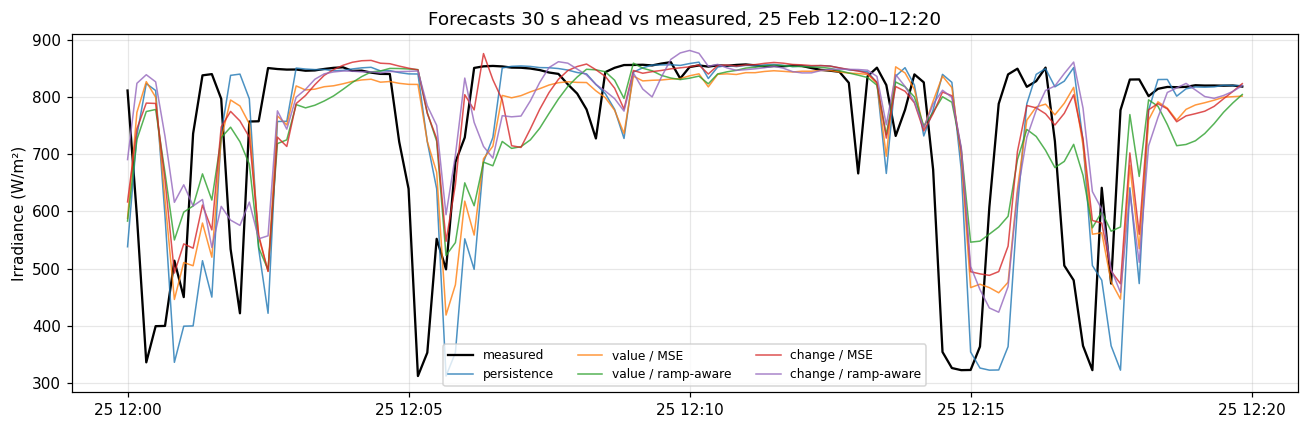

In [ ]:
# =====================================================================
# E) What the forecasts look like: 20 minutes on the broken-cloud test day
# =====================================================================
LEAD_SHOW = 30                                         # lead time to show (s): 10, 20, ..., 60
k = list(LEADS).index(LEAD_SHOW)
t_target = t_te + pd.Timedelta(seconds=LEAD_SHOW)      # the time each forecast is for
show = (t_target >= "2013-02-25 12:00") & (t_target < "2013-02-25 12:20")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_target[show], Y_te[show, k], color="k", lw=1.5, label="measured")
for name, P in forecasts.items():
    ax.plot(t_target[show], P[show, k], lw=1, alpha=0.8, label=name)
ax.set_ylabel("Irradiance (W/m²)")
ax.set_title(f"Forecasts {LEAD_SHOW} s ahead vs measured, 25 Feb 12:00–12:20")
ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.show()

**Results: what the forecasts look like (30 s ahead, 25 Feb 12:00–12:20)**

- **Persistence** is the measured curve shifted by 30 s: every drop appears 30 s late.
- **The LSTMs mostly react to clouds instead of foreseeing them.** At the large drops (around 12:05 and 12:15), none of the LSTMs falls before the measured irradiance does; they start falling at about the same time as persistence. With past irradiance as the only input, the arrival of a cloud cannot be seen in advance, which agrees with the data exploration (the timing of a ramp is hardly predictable from the past).
- **The LSTMs have learned that shadows are short.** After a drop, persistence stays at the low value (about 330 W/m² at 12:15:30), while the LSTMs predict a partial recovery (about 430–550 W/m²). This matches the short shade periods found in the data exploration (median 20 s) and explains why the LSTMs have a lower RMSE than persistence on the broken-cloud day.
- **Short dips are missed**, e.g. the dip at about 12:13, which appears in all forecasts only after it happened.
- **At 30 s the four LSTMs are close together.** *change / ramp-aware* shows additional ups and downs during calm periods (e.g. about 880 W/m² around 12:09–12:10), which correspond to its false alarms.

We suppose that many of the ramps "caught" by the ramp-aware models are recoveries after a drop rather than the drops themselves; this is checked by computing recall separately for drops and rises.

## Experiments (updated after E1)

E1 showed that (1) predicting the change instead of the value did not improve the forecasts, (2) the ramp-aware loss with λ = 1 makes the LSTM detect ramps but costs accuracy, and (3) with irradiance as the only input, the models react to clouds rather than foresee them. The plan is adjusted accordingly:

| | Question | What changes |
|---|---|---|
| **E1** (done, 1 seed) | 1, 2 | target (value vs change) × loss (MSE vs ramp-aware), irradiance only |
| **E1b** | 1, 2 | two more seeds; recall reported separately for drops and rises |
| **E2** | 4 | weight λ of the ramp term (0, 0.1, 0.3, 1, 3), value target; λ chosen on the validation day |
| **E3** | 3 | input groups, each added on its own to the univariate model: clear-sky index, recent variability, time of day, 1-s detail; then the best groups together |
| **E4** | 5 | each broken-cloud day used as the test day in turn, final setup |

From E2 on, only the value target is used, unless E1b shows otherwise. All experiments report MAE, RMSE, MAPE, R², MASE and the ramp counts, including recall for drops and rises separately.